# Eight QML experiments: GroupMemory versus equally informed Qiskit

This notebook reads the saved 16-condition local CPU benchmark. **Run All launches no simulations.** It validates the published summaries and reconstructs the figures from numeric records. The runnable experiments and exact resume command are in `docs/eight_experiments.md`.

Expected readout runtime: seconds. Inputs: `results/eight-experiments/`. Checkpoints for the original run: `results/eight-experiments/checkpoints/manifest.json`. To conduct a new run, use a new output directory; the original run deadline is immutable.

The primary comparison gives Qiskit the **same symmetry, equivalent jobs, native compilation and simulator**. Each method is measured in a fresh process, including startup, imports, computation and output writing. All examples are synthetic ideal simulations; none ran on a QPU.

## Measured findings

All **960 invocations** and **240 matched quantum blocks** passed. **Zero of sixteen conditions** met the predefined timing-win rule against equally informed Qiskit. Both implementations received identical quantum-work savings.

The strongest benefit over ordinary exact caching was sensor training (**3.46×** paired total-process speedup; **87.5%** fewer simulated forward CNOTs), followed by shared-weight gradients (**2.84×**; **80.5%** fewer simulated CNOTs). These are useful symmetry-reuse cases, but the equally informed Qiskit wrapper obtains essentially the same benefit.

Raw joint-symmetry kernels were a negative case: the scaled case prepared more representative states and was slower than ordinary exact caching. Image patches and the large-width local model did not produce a qualifying total-runtime win. The figures below show the measured scores and every baseline, including these negative cases.

## Load the measured evidence

Five data seeds and three timing repeats are planned for each of sixteen conditions. A seed enters a comparison only when all matching quantum trials passed. The saved vectors must agree within absolute tolerance $10^{-10}$. Related views are not independent test samples.

In [1]:
%matplotlib inline
from pathlib import Path
import json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd()
candidates = [here, *here.parents, here/'group-memory-qml']
ROOT = next(path for path in candidates if (path/'src/group_memory_qml').is_dir())
DATA = ROOT / 'results' / 'eight-experiments'
analysis = json.loads((DATA / 'analysis.json').read_text())
config = json.loads((DATA / 'config.json').read_text())
summary = analysis['summary']
comparisons = analysis['comparisons']
assert analysis['successful'] == analysis['planned']
assert analysis['validation_passed'] == analysis['validation_planned']
assert analysis['maximum_absolute_error'] <= 1e-10
print(f"{analysis['successful']} successful attempts; {analysis['validation_passed']} matched blocks")
print(f"Maximum output disagreement: {analysis['maximum_absolute_error']:.3g}")
environment = json.loads((DATA / 'environment.json').read_text())
print('Environment:', environment['platform'], environment['machine'], '; one thread per sequential worker; ideal CPU simulation')


960 successful attempts; 240 matched blocks
Maximum output disagreement: 2.31e-13
Environment: macOS-26.6.2-arm64-arm-64bit-Mach-O arm64 ; one thread per sequential worker; ideal CPU simulation


### Independently check the published raw records

The archive preserves every measured worker record. This cell verifies full coverage, frozen source identities, identical datasets across all four methods and all repetitions, and matching saved quantum outputs. It launches no new computation jobs.

In [2]:
import hashlib, zipfile
with zipfile.ZipFile(DATA / 'raw_attempts.zip') as archive:
    raw_names = sorted(name for name in archive.namelist() if name.startswith('attempts/') and name.endswith('.json'))
    raw_bytes = [archive.read(name) for name in raw_names]
records = [json.loads(value) for value in raw_bytes]
assert len(records) == len(config['plan']) == analysis['planned']
data_identities = {}
blocks = {}
for expected, row in zip(config['plan'], records):
    assert row['spec'] == expected and row['status'] == 'SUCCESS'
    assert row['source_hashes'] == config['source_hashes']
    family = expected['experiment'][0]
    if family == '1': fingerprint = row['diagnostics']['dataset_sha256']
    elif family == '2': fingerprint = row['diagnostics']['data_sha256']
    elif family == '3': fingerprint = row['validation_fingerprint']
    else: fingerprint = row['diagnostics']['data_fingerprint']
    key = (expected['condition'],expected['seed'])
    data_identities.setdefault(key,set()).add(fingerprint)
    blocks.setdefault((*key,expected['repeat']),{})[expected['method']] = row
assert all(len(values)==1 for values in data_identities.values())
maximum_error = 0.
for block in blocks.values():
    group = np.asarray(block['group_memory']['validation_vector'])
    for method in ('qiskit_symmetry','qiskit_exact'):
        other = np.asarray(block[method]['validation_vector'])
        assert other.shape == group.shape
        maximum_error = max(maximum_error,float(np.max(np.abs(group-other))))
    assert block['group_memory']['total_cx'] == block['qiskit_symmetry']['total_cx']
assert maximum_error <= 1e-10
with zipfile.ZipFile(DATA / 'source_snapshot.zip') as archive:
    for name, expected_hash in config['source_hashes'].items():
        assert hashlib.sha256(archive.read('group_memory_qml/'+name)).hexdigest() == expected_hash
manifest = json.loads((DATA/'checkpoints/manifest.json').read_text())
checkpoint_bytes = (DATA/'checkpoints'/manifest['latest']).read_bytes()
assert hashlib.sha256(checkpoint_bytes).hexdigest() == manifest['latest_sha256']
checkpoint = json.loads(checkpoint_bytes)
assert hashlib.sha256((DATA/'config.json').read_bytes()).hexdigest() == checkpoint['config_sha256']
assert hashlib.sha256(raw_bytes[-1]).hexdigest() == checkpoint['last_result_sha256']
print(f'Verified {len(records)} worker records, {len(data_identities)} matched dataset identities, maximum discrepancy {maximum_error:.3g}')


Verified 960 worker records, 80 matched dataset identities, maximum discrepancy 2.31e-13


## What actually won?

A descriptive win requires at least five complete seeds, every seed median faster, and median paired saving of at least 5%. This is a fixed descriptive rule, not a statistical confidence or universal crossover claim. A startup-dominated win over a different classical implementation does not establish a learning advantage.

In [3]:
primary = [r for r in comparisons if r['baseline'] == 'qiskit_symmetry']
winners = [r['condition'] for r in primary if r['descriptive_win']]
display(Markdown('**Eligible total-process wins over equally informed Qiskit:** ' + (', '.join(winners) if winners else 'none.')))
rows = ['|Condition|Group seconds|Symmetry-Qiskit seconds|Classical seconds|Group/classical task score|', '|---|---:|---:|---:|---|']
for condition in config['conditions']:
    lookup = {r['method']:r for r in summary if r['condition'] == condition['id']}
    g,q,c = (lookup[m] for m in ('group_memory','qiskit_symmetry','classical'))
    rows.append(f"|{condition['id']}|{g['process_median_s']:.3f}|{q['process_median_s']:.3f}|{c['process_median_s']:.3f}|{g['metric_name']}: {g['metric_mean']:.4g} / {c['metric_mean']:.4g}|")
display(Markdown('\n'.join(rows)))


**Eligible total-process wins over equally informed Qiskit:** none.

|Condition|Group seconds|Symmetry-Qiskit seconds|Classical seconds|Group/classical task score|
|---|---:|---:|---:|---|
|1A-small|2.003|1.967|1.277|heldout_accuracy: 0.875 / 1|
|1A-scaled|3.108|3.005|1.529|heldout_accuracy: 0.925 / 1|
|1B-small|1.715|1.664|1.288|heldout_mse: 0.01765 / 0.01679|
|1B-scaled|1.878|1.736|1.297|heldout_mse: 0.01448 / 0.01358|
|2A-small|0.451|0.468|1.350|heldout_accuracy: 1 / 1|
|2A-scaled|0.720|0.738|1.307|heldout_accuracy: 1 / 1|
|2B-small|0.620|0.612|1.540|heldout_mse: 0.02347 / 0.007433|
|2B-scaled|0.966|0.981|1.480|heldout_mse: 0.02206 / 0.003322|
|3A-small|1.629|1.618|1.246|heldout_accuracy: 0.9875 / 0.75|
|3A-scaled|1.840|1.839|1.301|heldout_accuracy: 1 / 0.975|
|3B-small|1.572|1.669|1.341|heldout_accuracy: 1 / 0.75|
|3B-scaled|2.044|2.051|1.293|heldout_accuracy: 1 / 0.975|
|4A-small|1.602|1.546|1.342|heldout_accuracy: 0.9667 / 1|
|4A-scaled|1.824|1.568|1.309|heldout_accuracy: 1 / 1|
|4B-small|1.592|1.633|1.295|heldout_accuracy: 0.9667 / 0.9667|
|4B-scaled|1.559|1.566|1.260|heldout_accuracy: 0.9667 / 0.9667|

## Paired speed ratios across seeds

Each point is the median of five seed-level ratios. Each line spans the observed minimum and maximum seed ratio; **it is not a confidence interval**. Each seed ratio uses three matched fresh-process repetitions. Values above one favor GroupMemory. The equally informed baseline is the primary test; ordinary exact caching is an ablation.

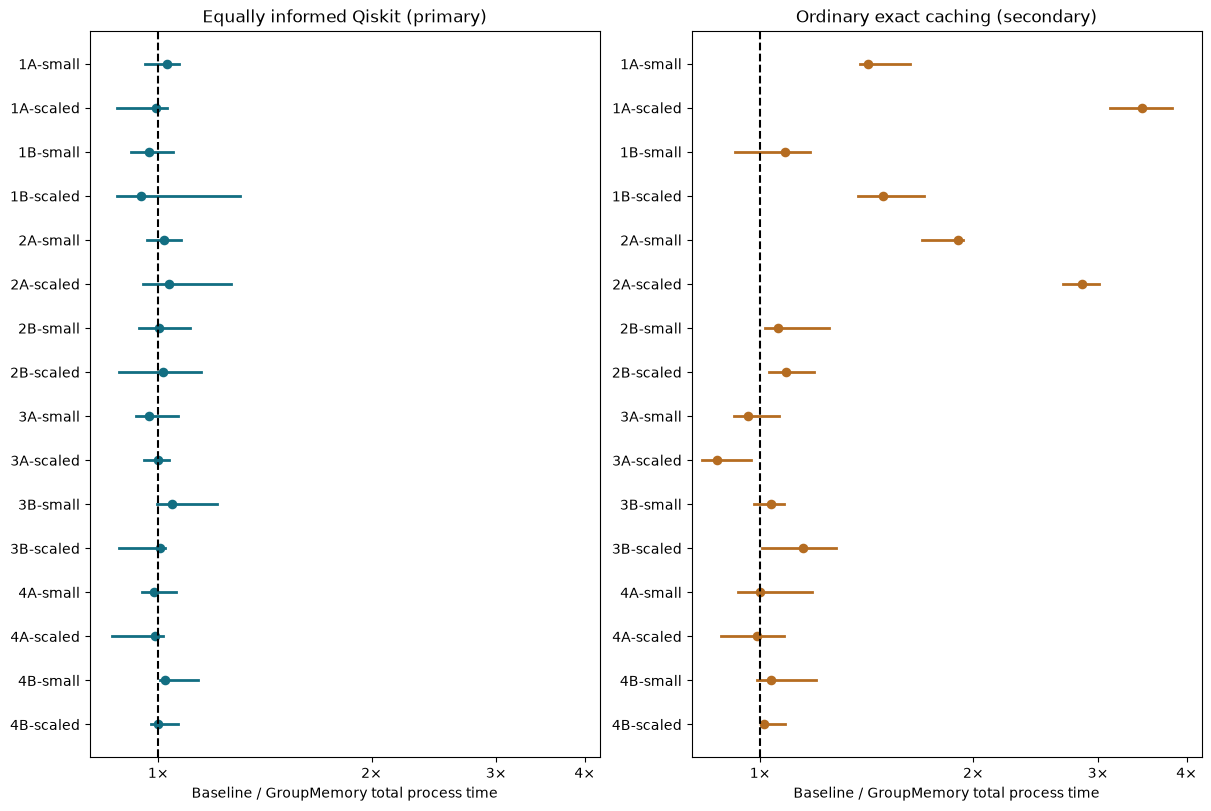

In [4]:
ids = [c['id'] for c in config['conditions']]
fig, axes = plt.subplots(1, 2, figsize=(12, 8), constrained_layout=True)
for ax, baseline, color in zip(axes, ['qiskit_symmetry','qiskit_exact'], ['#126e82','#b56c21']):
    rows = {r['condition']:r for r in comparisons if r['baseline'] == baseline}
    for i, cid in enumerate(ids):
        ratios = np.asarray(json.loads(rows[cid]['seed_speedups']))
        ax.plot([ratios.min(), ratios.max()], [i,i], color=color, linewidth=2)
        ax.scatter(np.median(ratios), i, color=color, marker='o', s=35)
    ax.axvline(1, color='black', linestyle='--')
    ax.set_yticks(range(len(ids)),ids); ax.invert_yaxis()
    ax.set_xscale('log'); ax.set_xlim(.8,4.2); ax.set_xticks([1,2,3,4], ['1×','2×','3×','4×']); ax.minorticks_off()
    ax.set_xlabel('Baseline / GroupMemory total process time')
    ax.set_title({'qiskit_symmetry':'Equally informed Qiskit (primary)', 'qiskit_exact':'Ordinary exact caching (secondary)'}[baseline])
fig.savefig(DATA / 'paired_seed_ranges.png', dpi=150)
plt.show()


## Learning quality

Accuracy is higher-is-better, with balanced chance at 50%. Mean squared error is lower-is-better. Scores average independent data seeds, not timing repetitions. These small synthetic test sets do not establish real-world generalization.

1A and 2A update quantum parameters; 2B uses Hessian updates. The other experiments train classical heads or SVMs over fixed features. In 4B, the analytic classical method computes the **same feature model** as the quantum cone simulation.

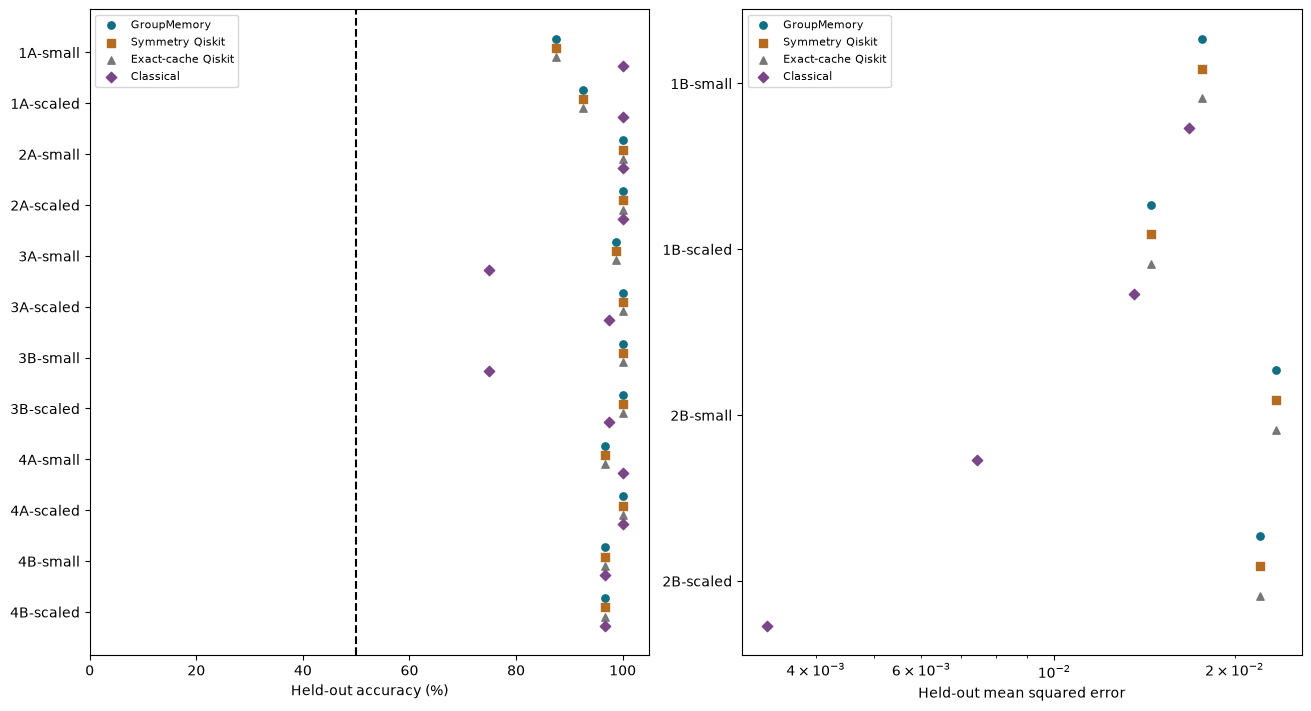

In [5]:
methods = ['group_memory','qiskit_symmetry','qiskit_exact','classical']
labels = ['GroupMemory','Symmetry Qiskit','Exact-cache Qiskit','Classical']
colors = ['#126e82','#b56c21','#777777','#7b4587']
fig, axes = plt.subplots(1, 2, figsize=(13, 7), constrained_layout=True)
for ax, want_accuracy in zip(axes,[True,False]):
    chosen = [cid for cid in ids if ('accuracy' in next(r['metric_name'] for r in summary if r['condition']==cid)) == want_accuracy]
    for j,(method,label,color) in enumerate(zip(methods,labels,colors)):
        lookup = {r['condition']:r for r in summary if r['method']==method}
        vals = [lookup[c]['metric_mean'] * (100 if want_accuracy else 1) for c in chosen]
        ax.scatter(vals,np.arange(len(chosen))+(j-1.5)*.18,label=label,color=color,marker=['o','s','^','D'][j],s=28)
    ax.set_yticks(range(len(chosen)),chosen);ax.invert_yaxis()
    if want_accuracy:
        ax.set_xlim(0,105);ax.axvline(50,color='black',linestyle='--');ax.set_xlabel('Held-out accuracy (%)')
    else:
        ax.set_xscale('log');ax.set_xlabel('Held-out mean squared error')
    ax.legend(fontsize=8)
fig.savefig(DATA / 'learning_quality.png',dpi=150)
plt.show()


## Simulated CNOT work

These counts cover gates in preparations/evaluations actually simulated. They are not hardware jobs, and avoiding repeated evaluations does not shorten each native circuit. The equally informed Qiskit wrapper must receive identical work savings. Kernel overlaps and reverse gradients are classical operations and are excluded from these gate counts.

In [6]:
with (DATA / 'seed_blocks.csv').open() as f:
    seed_blocks = list(csv.DictReader(f))
rows=['|Condition|Group simulated CX|Symmetry Qiskit CX|Exact-cache Qiskit CX|Median CX saving vs exact cache|','|---|---:|---:|---:|---:|']
for cid in ids:
    lookup={r['method']:r for r in summary if r['condition']==cid}
    g,q,e=(lookup[m]['total_cx_median'] for m in methods[:3])
    seeds={int(r['seed']) for r in seed_blocks if r['condition']==cid}
    b={(int(r['seed']),r['method']):r for r in seed_blocks if r['condition']==cid}
    savings=[1-float(b[(s,'group_memory')]['total_cx'])/float(b[(s,'qiskit_exact')]['total_cx']) for s in seeds if float(b[(s,'qiskit_exact')]['total_cx'])>0]
    assert g==q
    rows.append(f"|{cid}|{g:g}|{q:g}|{e:g}|{100*np.median(savings):.1f}%|")
display(Markdown('\n'.join(rows)))


|Condition|Group simulated CX|Symmetry Qiskit CX|Exact-cache Qiskit CX|Median CX saving vs exact cache|
|---|---:|---:|---:|---:|
|1A-small|480|480|1920|75.0%|
|1A-scaled|1600|1600|12800|87.5%|
|1B-small|512|512|2048|75.0%|
|1B-scaled|1152|1152|9216|87.5%|
|2A-small|2112|2112|10176|79.2%|
|2A-scaled|6528|6528|33408|80.5%|
|2B-small|5472|5472|6048|9.5%|
|2B-scaled|12204|12204|13500|9.6%|
|3A-small|984|984|384|-156.2%|
|3A-scaled|3488|3488|1024|-240.6%|
|3B-small|1152|1152|1152|0.0%|
|3B-scaled|4096|4096|4096|0.0%|
|4A-small|32|32|112|71.4%|
|4A-scaled|432|432|1536|70.3%|
|4B-small|384|384|768|50.0%|
|4B-scaled|384|384|768|50.0%|

## Why a cold-start classical loss is not quantum advantage

The primary comparison correctly includes each implementation's imports. In the tiny derivative tasks, scikit-learn startup can outweigh the actual classical fit. The separate diagnostic below imports dependencies first, then constructs fresh models and caches. It uses one new seed, is not a repeated timing study, and is **not pooled with the frozen benchmark**. Interpreter startup is excluded from this diagnostic. Reproduce it with `python examples/startup_diagnostic.py --output results/startup_diagnostic.json`.

In [7]:
diagnostic = json.loads((DATA/'startup_diagnostic.json').read_text())
lines=['|Task|Method|Application after eager dependency imports|Task score|','|---|---|---:|---:|']
for row in diagnostic['measurements']:
    lines.append(f"|{row['experiment']}|{row['method']}|{1000*row['application_after_dependency_import_s']:.1f} ms|{row['metric_value']:.5g}|")
display(Markdown('\n'.join(lines)))
print(f"Shared eager import stage: {diagnostic['import_stage_s']:.3f} seconds (reported separately)")


|Task|Method|Application after eager dependency imports|Task score|
|---|---|---:|---:|
|2A|classical|27.9 ms|1|
|2A|group_memory|410.4 ms|1|
|2B|classical|17.7 ms|0.0012059|
|2B|group_memory|629.7 ms|0.019899|

Shared eager import stage: 3.159 seconds (reported separately)


## Accounting and limitations

The primary total clock includes interpreter startup, imports, source hashing, data generation, compilation, canonicalization, simulation, training, predictions, result writing and shutdown. The subsidiary application clock includes lazy imports and is not a clean steady-state compute benchmark. Package installation is excluded. Independent tests, the checkpoint pilot, parent orchestration and readout creation are recorded separately.

The 256-site experiment uses a connected shallow ring with exact three-qubit backward cones; it does not construct a 256-qubit statevector. Its analytic classical control is an exact model-equivalent comparison. Reused finite-shot estimates on hardware would introduce correlated errors, and noise can break ideal symmetries. Those effects are not tested here.

In [8]:
print(f"Sum of all measured fresh-process walls: {analysis['process_wall_sum_s']:.3f} seconds")
print(f"Campaign wall including its parent/journal: {analysis['status']['elapsed_since_first_start_s']:.3f} seconds")
receipt = DATA / 'suite_wall_accounting.json'
if receipt.exists():
    print(json.dumps(json.loads(receipt.read_text()), indent=2))


Sum of all measured fresh-process walls: 1733.505 seconds
Campaign wall including its parent/journal: 1736.738 seconds
{
  "main_successful_invocations": 960,
  "main_matched_quantum_blocks": 240,
  "main_sum_fresh_process_wall_s": 1733.5048990872456,
  "main_monotonic_loop_wall_s": 1736.804236667056,
  "main_parent_journal_between_attempts_s": 3.299337579810526,
  "independent_test_process_s": 9.471230625000317,
  "pilot_elapsed_including_resume_pause_s": 132.93196988105774,
  "quick_functional_smoke_loop_s": 43.62755020795157,
  "separate_diagnostic_clocks_s": [
    3.97908933297731,
    4.3121482920250855
  ],
  "main_report_clock_s": 1.1616531669860706,
  "quick_report_clock_s": 0.762567957979627,
  "initial_packaging_clock_s": 0.8490067080128938,
  "scope": "Each primary method clock includes full interpreter startup through exit. Main loop wall includes parent parsing/journaling between attempts; initial parent imports/argument parsing precede this loop clock. Installation and hu